# Mathematical morphology

In [1]:
import numpy as np
import skimage.io as io
import matplotlib.pyplot as plt
import skimage.morphology as mo
import scipy.ndimage as smo
from skimage import measure
from skimage import img_as_ubyte, img_as_float
from skimage.measure import label, regionprops

plt.style.use('../../src/bip.mplstyle')
import matplotlib as mpl
mpl.rcParams['xtick.bottom']      = False
mpl.rcParams['xtick.top']         = False
mpl.rcParams['xtick.labelbottom'] = False
mpl.rcParams['ytick.left']        = False
mpl.rcParams['ytick.right']       = False
mpl.rcParams['ytick.labelleft']   = False
mpl.rcParams['font.size']         = 16

## Operations on sets

In [ ]:
A = io.imread("A.png")
B = io.imread("B.png")
C = np.invert(A)
U = np.bitwise_or(A,B)
I = np.bitwise_and(A,B)
D = np.bitwise_and(A,np.invert(B))

# def myplot(no, img, title):
#     plt.subplot(2,3,no)
#     plt.imshow(img, "gray")
#     plt.rc('text', usetex=True)
#     plt.rc('font', family='serif')
#     plt.xlabel(title, size=16)
#     plt.xticks([])
#     plt.yticks([])

# fig = plt.figure(figsize=(10,7))
# myplot(1, A, "$A$")
# myplot(2, B, "$B$")
# myplot(3, D, r"$A \setminus B$")
# myplot(4, C, r"$A^\mathrm{c}$")
# myplot(5, U, r"$A\cup B$")
# myplot(6, I, r"$A\cap B$")
# plt.show()

# Ajoute un cadre autour de C
C[0,:] = 0
C[-1,:] = 0
C[:,0] = 0
C[:,-1] = 0

io.imsave("set-A.png", A)
io.imsave("set-B.png", B)
io.imsave("set-complement.png", C)
io.imsave("set-difference.png", D)
io.imsave("set-union.png", U)
io.imsave("set-intersection.png", I)

## Neighborhood and connectivity

In [ ]:
# Toy image
img = np.array([ \
    [0, 0, 0, 1, 0, 0, 0], \
    [0, 0, 0, 1, 1, 1, 0], \
    [0, 0, 1, 0, 0, 1, 0], \
    [0, 1, 1, 1, 1, 0, 0],
    [0, 1, 1, 0, 0, 0, 0] ])
M, N = img.shape

# Dilation
fig, ax = plt.subplots(1, 1, figsize=(6,3))
ax.imshow(img, "gray")    
ax.set_xticks(np.arange(.50, N-1), minor=True)
ax.set_yticks(np.arange(.50, M-1), minor=True)
ax.grid(which='minor', color='#cccccc', linewidth=1)
plt.savefig("connectivity.svg", bbox_inches='tight')

In [ ]:
# Taille de l'image
N = 5

# Pixel central, avec un décalage pour l'affichage
o = (N-1)//2 + .5

# Voisins
neighbors = [ (+1, 0), (-1, 0), ( 0,+1), ( 0,-1), (+1,+1), (+1,-1), (-1,+1), (-1,-1) ]

fig, axs = plt.subplots(1, 2, figsize=(6,3))

for i in range(2):

    # Pixel central
    axs[i].plot(o, o, marker="s", color="C0", markersize=25, alpha=.8)
    
    # Représentation du voisinage
    for neighbor in neighbors[:4*(i+1)]:
        axs[i].plot(o+neighbor[0], o+neighbor[1], marker="s", color="C2", markersize=25, alpha=.5)

    # Grille
    axs[i].axis('equal')
    axs[i].set_xticks(range(N+1))
    axs[i].set_yticks(range(N+1))
    axs[i].grid()

plt.savefig("neighborhood.svg", bbox_inches='tight')

## Basic operators & top-hat

In [ ]:
def display(img, title, grid=True, sec=None):
    plt.imshow(img, "gray")
    plt.xlabel(title, size=16)
    
    # Centre de l'élément structurant
    if sec != None:
        plt.plot(sec[0], sec[1], marker="o")
    
    # Grille
    if grid:
        ax = plt.gca()
        M, N = img.shape
        ax.set_xticks(np.arange(.50, N-1))
        ax.set_yticks(np.arange(.50, M-1))
        ax.grid(color='#cccccc', linewidth=1)

In [ ]:
# Toy image
I = np.array([ \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 1, 0, 0, 0], \
    [0, 0, 1, 0, 1, 1, 0], \
    [0, 0, 0, 1, 1, 1, 0], \
    [0, 1, 1, 1, 1, 0, 0], \
    [1, 0, 0, 1, 1, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0] ])

# Structuring element
E = np.array([ \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 1, 0, 0, 0], \
    [0, 0, 1, 1, 1, 0, 0], \
    [0, 0, 0, 1, 0, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0] ])

# Dilation
fig = plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
display(I, "$I$")
plt.subplot(1,3,2)
display(E, "$E_c$", sec=(3,3))
plt.subplot(1,3,3)
display(mo.binary_dilation(I,E), r"$I \oplus E_c$")
plt.savefig("dilation-toy.svg", bbox_inches='tight')

# Erosion
fig = plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
display(I, "$I$")
plt.subplot(1,3,2)
display(E, "$E_c$", sec=(3,3))
plt.subplot(1,3,3)
display(mo.binary_erosion(I,E), r"$I \ominus E_c$")
plt.savefig("erosion-toy.svg", bbox_inches='tight')

# Opening
fig = plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
display(I, "$I$")
plt.subplot(1,3,2)
display(E, "$E_c$", sec=(3,3))
plt.subplot(1,3,3)
display(mo.binary_opening(I,E), r"$I \circ E_c$")
plt.savefig("opening-toy.svg", bbox_inches='tight')

# Closing
fig = plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
display(I, "$I$")
plt.subplot(1,3,2)
display(E, "$E_c$", sec=(3,3))
plt.subplot(1,3,3)
display(mo.binary_closing(I,E), r"$I \bullet E_c$")
plt.savefig("closing-toy.svg", bbox_inches='tight')

In [ ]:
# Toy image
I = np.array([ \
    [0, 1, 0, 0, 0, 0, 0], \
    [0, 1, 0, 0, 0, 0, 0], \
    [0, 0, 0, 0, 1, 1, 0], \
    [0, 0, 1, 0, 0, 0, 0], \
    [1, 0, 0, 0, 0, 0, 0], \
    [1, 1, 1, 0, 1, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0] ])
Ic = 1 - I

# Structuring element 1
# E1 = np.array([[1, 1]])
E1 = np.array([ \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 1, 1, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0] ])

# Structuring element 2
# E2 = np.array([ \
#     [1, 1, 1, 1],
#     [1, 0, 0, 1], \
#     [1, 1, 1, 1] ])
E2 = np.array([ \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 1, 1, 1, 1, 0], \
    [0, 0, 1, 0, 0, 1, 0], \
    [0, 0, 1, 1, 1, 1, 0], \
    [0, 0, 0, 0, 0, 0, 0], \
    [0, 0, 0, 0, 0, 0, 0] ])

fig = plt.figure(figsize=(11,6))

# Erosion
plt.subplot(2,4,1)
display(I, "$I$")
plt.subplot(2,4,2)
display(E1, "$E_1$", sec=(3,3))
plt.subplot(2,4,3)
display(mo.binary_erosion(I,E1), r"$I \ominus E_1$")

# Erosion of the complement
plt.subplot(2,4,5)
display(Ic, r"$I^\mathrm{c}$")
plt.subplot(2,4,6)
display(E2, "$E_2$", sec=(3,3))
plt.subplot(2,4,7)
display(mo.binary_erosion(Ic,E2), r"$I^\mathrm{c} \ominus E_2$")

# Hit-or-miss
# I1 = mo.binary_erosion(I,E1)
# I2 = mo.binary_erosion(Ic,E2)
# U = np.bitwise_and(I1,I2)
# plt.subplot(3,3,8)
# display(U, "")
plt.subplot(1,4,4)
display(smo.binary_hit_or_miss(I,E1, E2), r"$I \otimes (E_1,E_2)$")

plt.savefig("hit-or-miss-toy.svg", bbox_inches='tight')

## Top-hat

In [ ]:
# Image
img = io.imread("vermicelli.png")/255

# Structuring element
E = mo.disk(3)

# Add the structuring element in the image
N = E.shape[0]
d = 5
img[-N-d:-d,-N-d:-d] = E

# White top-hat
Tw = img - mo.binary_opening(img,E).astype(np.uint8)
  
# Black top-hat
Tb = mo.binary_closing(img,E).astype(np.uint8) - img

# Affichage
fig, axs = plt.subplots(1,3,figsize=(15,5))
axs[0].imshow(img, "gray")
axs[0].set_title("Original image")
axs[1].imshow(Tw, "gray")
axs[1].set_title("White top-hat")
axs[2].imshow(Tb, "gray")
axs[2].set_title("Black top-hat")
for i in range(3):
    axs[i].set_xticks([])
    axs[i].set_yticks([])
plt.savefig("top-hat.svg", bbox_inches='tight')
plt.show()

## Granulometry

In [ ]:
# Image
img = io.imread("grains.png")
N = img.shape[0]

# Élément structurant de base
E = mo.disk(3)

# Nombre d'étapes
K = 8

# Ouvertures successives
res = [np.zeros((N,N,K))] * K
granulometry = np.zeros(K)
size = np.zeros(K)
for k in range(K):

    # Élément structurant
    size[k] = int(3*(k+1))
    Ek = mo.disk(size[k])

    # Ouverture
    res[k] = mo.binary_opening(img, Ek)
    
    # Calcul de la granulométrie
    granulometry[k] = np.sum(res[k].ravel())

# Affichage des images
fig, axs = plt.subplots(3, 3, figsize=(10,10))
axs = axs.ravel()
axs[0].imshow(img, "gray")
axs[0].set_title("Original image")
for k in range(K):
    axs[k+1].imshow(res[k], "gray")
    axs[k+1].set_title(f"size = {size[k]:.0f}")
plt.savefig("granulometry-images.svg", bbox_inches='tight')
plt.show()

# Affichage de la granulométrie et de sa distribution
fig = plt.figure(figsize=(6,3))
plt.plot(size, granulometry, '-o')
plt.xticks(size)
plt.xlabel("Disk size")
plt.ylabel("Granulometry")
plt.gca().tick_params(
    axis='both',  # Concerne à la fois l'axe X et l'axe Y
    bottom=True,  # Affiche le tick en bas (X)
    labelbottom=True,  # Affiche le libellé en bas (X)
    left=True,  # Affiche le tick à gauche (Y)
    labelleft=True,  # Affiche le libellé à gauche (Y)
)
plt.savefig("granulometry-plot.svg", bbox_inches='tight')
plt.show()

## Skeleton

In [ ]:
# import skimage.data as data

# img = 1 - data.horse()
img = io.imread("dobble-key.png")
sk = mo.skeletonize(img)

# Affichage
fig, axs = plt.subplots(1,2,figsize=(10,5))
axs[0].imshow(img, "gray")
axs[0].set_title("Original image")
axs[1].imshow(sk, "gray")
axs[1].set_title("Skeleton")
for i in range(2):
    axs[i].set_xticks([])
    axs[i].set_yticks([])
plt.savefig("skeleton.svg", bbox_inches='tight')
plt.show()

## Operations on Greece

In [ ]:
# Real image ans structuring element
img = io.imread("greece.png")
se = mo.disk(4)

io.imsave("greece-dilation.png", img_as_ubyte(mo.binary_dilation(img,se)))
io.imsave("greece-erosion.png",  img_as_ubyte(mo.binary_erosion(img,se) ))
io.imsave("greece-opening.png",  img_as_ubyte(mo.binary_opening(img,se) ))
io.imsave("greece-closing.png",  img_as_ubyte(mo.binary_closing(img,se) ))

## Measures

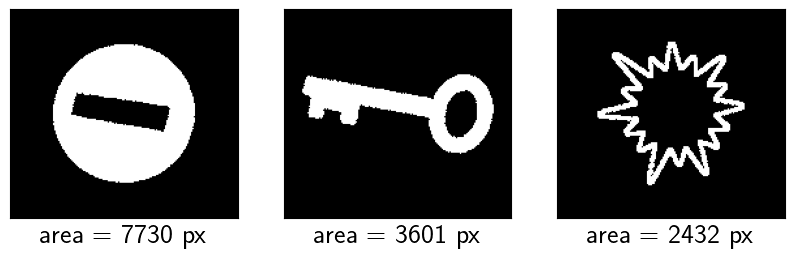

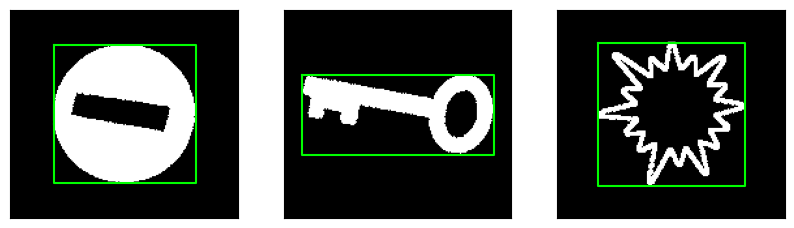

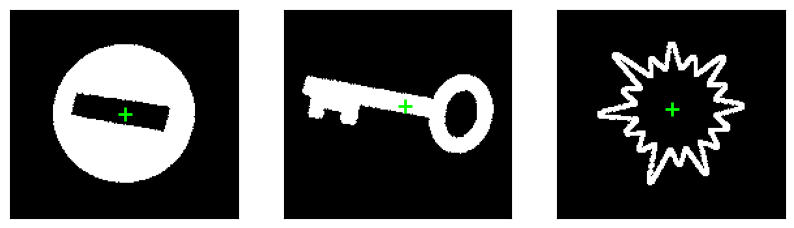

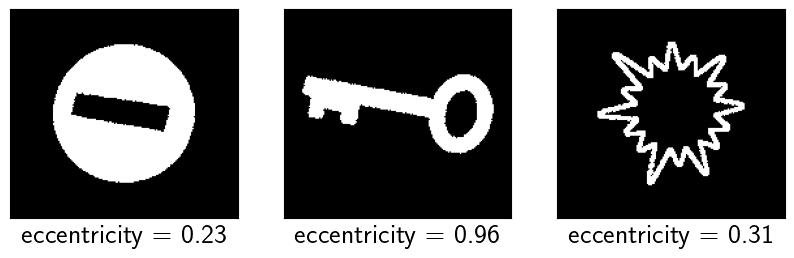

1
1
1


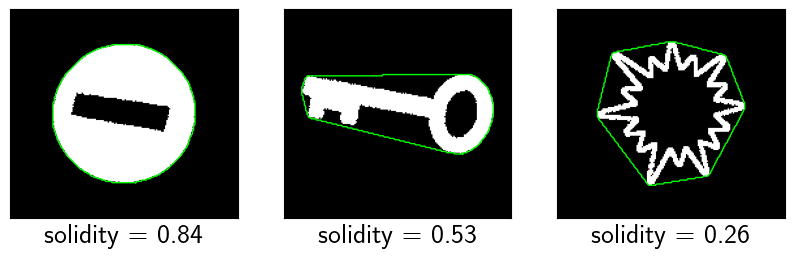

In [ ]:
props = [ "area", "bbox", "centroid", "eccentricity", "solidity" ]
imgs = [ "noway", "key", "sun" ]
N = len(imgs)

for prop in props:
    
    fig, axs = plt.subplots(1,N, figsize=(10,5))
    for i in range(N):
        
        # Chargement et affichage de l'image
        img = io.imread(f'dobble-{imgs[i]}.png')
        axs[i].imshow(img, cmap="gray")
        
        properties = regionprops(img)[0]
    
        if prop == "area":
            axs[i].set_xlabel(f"area = {properties.area:.0f} px", size=20)
    
        if prop == "bbox":
            ymin, xmin, ymax, xmax = properties.bbox
            axs[i].plot([xmin, xmax, xmax, xmin, xmin], [ymin, ymin, ymax, ymax, ymin], '#00ff00')
    
        if prop == "centroid":
            y, x = properties.centroid
            axs[i].plot(x, y, color='#00ff00', marker='+', markersize=10, markeredgewidth=2)
    
        if prop == "eccentricity":
            axs[i].set_xlabel(f"eccentricity = {properties.eccentricity:.2f}", size=20)
    
        if prop == "solidity":
            ch = mo.convex_hull_image(img)
            contours = measure.find_contours(ch.astype(float), level=0.5)
            for contour in contours:
                axs[i].plot(contour[:, 1], contour[:, 0], linewidth=1, color='#0f0')
            axs[i].set_xlabel(f"solidity = {properties.solidity:.2f}", size=20)
    
    plt.show()
    fig.savefig(f"prop-{prop}.svg", bbox_inches='tight')